In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [2]:
df = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv')

In [3]:
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [4]:
df1 = df[['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year', 'fuel_efficiency_mpg']]


In [5]:
df1

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0
...,...,...,...,...,...
9995,2470,271.0,4690,2005,27.4
9996,2300,244.0,4370,1993,30.0
9997,2480,267.0,4590,2014,28.1
9998,2180,270.0,4450,2004,32.2


In [6]:
df2 = df1.copy()
df3 = df1.copy()
df4 = df1.copy()
df5 = df1.copy()
df6 = df1.copy()

In [7]:
df2

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0
...,...,...,...,...,...
9995,2470,271.0,4690,2005,27.4
9996,2300,244.0,4370,1993,30.0
9997,2480,267.0,4590,2014,28.1
9998,2180,270.0,4450,2004,32.2


-----------------------------------------------------------------------------------------------------------------------------

In [8]:
columns_with_nan = df1.isna().any()
print("Columns with at least one NaN value:\n", columns_with_nan)

Columns with at least one NaN value:
 engine_displacement    False
horsepower              True
vehicle_weight         False
model_year             False
fuel_efficiency_mpg    False
dtype: bool


### Q1 Horsepower is the column with missing values

In [9]:
median_horsepower = df1['horsepower'].median()

In [10]:
print(f"Median of 'horsepower': {median_horsepower}")

Median of 'horsepower': 254.0


### Q2 Median of horsepower column is 254

In [11]:
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   engine_displacement  10000 non-null  int64  
 1   horsepower           9123 non-null   float64
 2   vehicle_weight       10000 non-null  int64  
 3   model_year           10000 non-null  int64  
 4   fuel_efficiency_mpg  10000 non-null  float64
dtypes: float64(2), int64(3)
memory usage: 390.8 KB


-----------------------------------------------------------------------------------------------------------------------

In [12]:
np.random.seed(42)

n = len(df1)

n_val = int(0.2 * n)
n_test = int(0.2 * n)
n_train = n - (n_val + n_test)

idx = np.arange(n)
np.random.shuffle(idx)

df_shuffled = df1.iloc[idx]

df_train = df_shuffled.iloc[:n_train].copy()
df_val = df_shuffled.iloc[n_train:n_train+n_val].copy()
df_test = df_shuffled.iloc[n_train+n_val:].copy()

In [13]:
y_train_orig = df_train.fuel_efficiency_mpg.values
y_val_orig = df_val.fuel_efficiency_mpg.values
y_test_orig = df_test.fuel_efficiency_mpg.values

y_train = np.log1p(df_train.fuel_efficiency_mpg.values)
y_val = np.log1p(df_val.fuel_efficiency_mpg.values)
y_test = np.log1p(df_test.fuel_efficiency_mpg.values)

del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [ ]:
np.random.seed(42)

n = len(df1)

n_val = int(0.2 * n)
n_test = int(0.2 * n)
n_train = n - (n_val + n_test)

idx = np.arange(n)
np.random.shuffle(idx)

df_shuffled = df1.iloc[idx]

df_train = df_shuffled.iloc[:n_train].copy()
df_val = df_shuffled.iloc[n_train:n_train+n_val].copy()
df_test = df_shuffled.iloc[n_train+n_val:].copy()

y_train_orig = df_train.fuel_efficiency_mpg.values
y_val_orig = df_val.fuel_efficiency_mpg.values
y_test_orig = df_test.fuel_efficiency_mpg.values

y_train = np.log1p(df_train.fuel_efficiency_mpg.values)
y_val = np.log1p(df_val.fuel_efficiency_mpg.values)
y_test = np.log1p(df_test.fuel_efficiency_mpg.values)

#### Linear Regression

In [14]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv.dot(X.T).dot(y)
    
    return w[0], w[1:]

#### Baseline solution

In [15]:
base = ['horsepower']


In [16]:
def prepare_X(df):
    df_num = df[base]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

In [17]:
X_train = prepare_X(df_train)
w_0, w = train_linear_regression(X_train, y_train)

In [18]:
y_pred = w_0 + X_train.dot(w)

Text(0.5, 1.0, 'Predictions vs actual distribution')

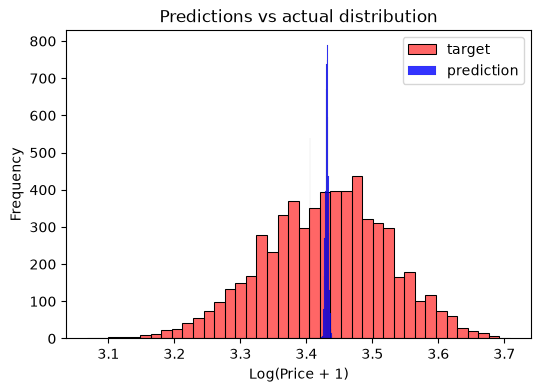

In [19]:
plt.figure(figsize=(6, 4))

sns.histplot(y_train, label='target', color='red', alpha=0.6, bins=40)
sns.histplot(y_pred, label='prediction', color='blue', alpha=0.8, bins=40)

plt.legend()

plt.ylabel('Frequency')
plt.xlabel('Log(Price + 1)')
plt.title('Predictions vs actual distribution')


In [20]:
def rmse(y, y_pred):
    error = y_pred - y
    mse = (error ** 2).mean()
    return np.sqrt(mse)

In [21]:
rmse(y_train, y_pred)


np.float64(0.09503425842911821)

----------------------------------------------------------------------------------------------------------------------------

In [22]:
np.random.seed(42)

n = len(df2)

n_val2 = int(0.2 * n)
n_test2 = int(0.2 * n)
n_train2= n - (n_val2 + n_test2)

idx = np.arange(n)
np.random.shuffle(idx)

df_shuffled2 = df2.iloc[idx]

df_train2 = df_shuffled2.iloc[:n_train2].copy()
df_val2 = df_shuffled2.iloc[n_train2:n_train2+n_val2].copy()
df_test2 = df_shuffled2.iloc[n_train2+n_val2:].copy()

In [23]:
y_train_orig2 = df_train2.fuel_efficiency_mpg.values
y_val_orig2 = df_val2.fuel_efficiency_mpg.values
y_test_orig2 = df_test2.fuel_efficiency_mpg.values

y_train2 = np.log1p(df_train2.fuel_efficiency_mpg.values)
y_val2 = np.log1p(df_val2.fuel_efficiency_mpg.values)
y_test2= np.log1p(df_test2.fuel_efficiency_mpg.values)

del df_train2['fuel_efficiency_mpg']
del df_val2['fuel_efficiency_mpg']
del df_test2['fuel_efficiency_mpg']

In [24]:
def prepare_X1(df):
    df_num = df[base]
    df_num = df_num.fillna(149)
    X = df_num.values
    return X

In [25]:
X_train2 = prepare_X1(df_train2)
w_0, w = train_linear_regression(X_train2, y_train2)

In [26]:
y_pred2 = w_0 + X_train2.dot(w)

Text(0.5, 1.0, 'Predictions vs actual distribution')

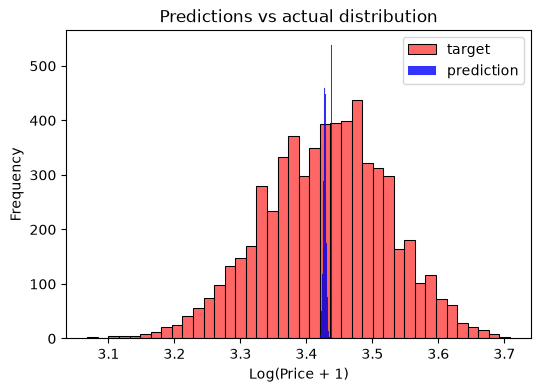

In [27]:
plt.figure(figsize=(6, 4))

sns.histplot(y_train2, label='target', color='red', alpha=0.6, bins=40)
sns.histplot(y_pred2, label='prediction', color='blue', alpha=0.8, bins=40)

plt.legend()

plt.ylabel('Frequency')
plt.xlabel('Log(Price + 1)')
plt.title('Predictions vs actual distribution')


In [28]:
def rmse(y, y_pred):
    error = y_pred - y
    mse = (error ** 2).mean()
    return np.sqrt(mse)

In [29]:
rmse(y_train2, y_pred2)


np.float64(0.09527616134952106)

### Q3 WITH MEAN 

-------------------------------------------------------------------------------------------------------------------------

In [30]:
df3

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0
...,...,...,...,...,...
9995,2470,271.0,4690,2005,27.4
9996,2300,244.0,4370,1993,30.0
9997,2480,267.0,4590,2014,28.1
9998,2180,270.0,4450,2004,32.2


#### Regularization

In [30]:
def prepare_X(df):
    df_num = df[base]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

In [31]:
def train_linear_regression_reg(X, y, r=0.0):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    reg = r * np.eye(XTX.shape[0])
    XTX = XTX + reg

    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv.dot(X.T).dot(y)
    
    return w[0], w[1:]

In [32]:
np.random.seed(42)

n = len(df3)

n_val3 = int(0.2 * n)
n_test3 = int(0.2 * n)
n_train3= n - (n_val3 + n_test3)

idx = np.arange(n)
np.random.shuffle(idx)

df_shuffled3 = df3.iloc[idx]

df_train3 = df_shuffled3.iloc[:n_train3].copy()
df_val3 = df_shuffled3.iloc[n_train3:n_train3+n_val3].copy()
df_test3 = df_shuffled3.iloc[n_train3+n_val3:].copy()

In [33]:
y_train_orig3 = df_train3.fuel_efficiency_mpg.values
y_val_orig3 = df_val3.fuel_efficiency_mpg.values
y_test_orig3 = df_test3.fuel_efficiency_mpg.values

y_train3 = np.log1p(df_train3.fuel_efficiency_mpg.values)
y_val3 = np.log1p(df_val3.fuel_efficiency_mpg.values)
y_test3= np.log1p(df_test3.fuel_efficiency_mpg.values)

del df_train3['fuel_efficiency_mpg']
del df_val3['fuel_efficiency_mpg']
del df_test3['fuel_efficiency_mpg']

In [35]:
X_train3 = prepare_X1(df_train3)
w_0, w = train_linear_regression(X_train3, y_train3)

In [34]:
X_train = prepare_X(df_train)

In [35]:
for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    w_0, w = train_linear_regression_reg(X_train, y_train, r=r)
    y_pred = w_0 + X_train.dot(w)
    rmse(y_train, y_pred)
    print(r, rmse(y_train, y_pred))
    #print('%5s, %.2f, %.2f, %.2f' % (r, w_0, w[0], w[0]))

0 0.09503425842911821
0.01 0.09503426017918351
0.1 0.0950344333812841
1 0.09505169799481498
5 0.09546338644047654
10 0.09671086991241995
100 0.182329167463691


In [36]:
X_train = prepare_X(df_train)
w_0, w = train_linear_regression_reg(X_train, y_train, r=0)

y_pred = w_0 + X_train.dot(w)
print('train', rmse(y_train, y_pred))

X_val = prepare_X(df_val)
y_pred = w_0 + X_val.dot(w)
print('val', rmse(y_val, y_pred))

train 0.09503425842911821
val 0.09374019281503837


In [37]:
X_train = prepare_X(df_train)
w_0, w = train_linear_regression_reg(X_train, y_train, r=0.01)

y_pred = w_0 + X_train.dot(w)
print('train', rmse(y_train, y_pred))

X_val = prepare_X(df_val)
y_pred = w_0 + X_val.dot(w)
print('val', rmse(y_val, y_pred))

train 0.09503426017918351
val 0.09374073957681404


In [38]:
X_train = prepare_X(df_train)
X_val = prepare_X(df_val)

for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    w_0, w = train_linear_regression_reg(X_train, y_train, r=r)
    y_pred = w_0 + X_val.dot(w)
    print('%6s' %r, rmse(y_val, y_pred))

     0 0.09374019281503837
  0.01 0.09374073957681404
   0.1 0.0937458170106226
     1 0.0938120285702891
     5 0.09443821241909618
    10 0.09594283670087983
   100 0.18319488935069772


In [39]:
X_train = prepare_X(df_train)
w_0, w = train_linear_regression_reg(X_train, y_train, r=0.01)

X_val = prepare_X(df_val)
y_pred = w_0 + X_val.dot(w)
print('validation:', rmse(y_val, y_pred))

X_test = prepare_X(df_test)
y_pred = w_0 + X_test.dot(w)
print('test:', rmse(y_test, y_pred))

validation: 0.09374073957681404
test: 0.09573343654659323


### Q4 WITH 0.001

-----------------------------------------------------------------------------------------------------------------------------

https://stats.stackexchange.com/questions/629452/accuracy-score-change-a-lot-by-changing-random-seed-in-train-test-split

In [43]:
result_rmse = []
for i in range(10):

    # Set a new seed
    # 
    np.random.seed(i)
    n3 = len(df3)
    
    n_val3 = int(0.2 * n3)
    n_test3 = int(0.2 * n3)
    n_train3 = n - (n_val3 + n_test3)
    
    idx = np.arange(n3)
    np.random.shuffle(idx)
    
    df_shuffled3 = df3.iloc[idx]
    
    df_train3 = df_shuffled3.iloc[:n_train3].copy()
    df_val3 = df_shuffled3.iloc[n_train3:n_train3+n_val3].copy()
    df_test3 = df_shuffled3.iloc[n_train3+n_val3:].copy()

    
    y_train_orig3 = df_train3.fuel_efficiency_mpg.values
    y_val_orig3 = df_val3.fuel_efficiency_mpg.values
    y_test_orig3 = df_test3.fuel_efficiency_mpg.values
    
    y_train3 = np.log1p(df_train3.fuel_efficiency_mpg.values)
    y_val3 = np.log1p(df_val3.fuel_efficiency_mpg.values)
    y_test3 = np.log1p(df_test3.fuel_efficiency_mpg.values)
    
    del df_train3['fuel_efficiency_mpg']
    del df_val3['fuel_efficiency_mpg']
    del df_test3['fuel_efficiency_mpg']
    # Run the rest of your code to split the data, train the model, 
    # and report the performance for seed i

    X_train3 = prepare_X(df_train3)
    w_0, w = train_linear_regression(X_train3, y_train3)

    y_pred3 = w_0 + X_train.dot(w)

    result_rmse.append((rmse(y_train3, y_pred3)))
    

In [44]:
result_rmse

[np.float64(0.09495764365933952),
 np.float64(0.09554556851271023),
 np.float64(0.0961265407213094),
 np.float64(0.0950167921412724),
 np.float64(0.09581186229306249),
 np.float64(0.09481038430306209),
 np.float64(0.09465780418962082),
 np.float64(0.09637958647847827),
 np.float64(0.09410343568652503),
 np.float64(0.09579459396526914)]

In [45]:
std_rmse = np.std(result_rmse)

std_rmse

### Q5 0.000685

### Question 6

In [48]:
np.random.seed(9)

n = len(df2)

#n_val = int(0.2 * n)
n_test = int(0.2 * n)
n_train = n - (n_val + n_test)

idx = np.arange(n)
np.random.shuffle(idx)

df_shuffled = df.iloc[idx]

df_train = df_shuffled.iloc[:n_train].copy()
#df_val = df_shuffled.iloc[n_train:n_train+n_val].copy()
df_test = df_shuffled.iloc[n_train+n_val:].copy()

In [49]:
y_train_orig = df_train.fuel_efficiency_mpg.values
#y_val_orig = df_val.fuel_efficiency_mpg.values
y_test_orig = df_test.fuel_efficiency_mpg.values

y_train = np.log1p(df_train.fuel_efficiency_mpg.values)
#y_val = np.log1p(df_val.fuel_efficiency_mpg.values)
y_test = np.log1p(df_test.fuel_efficiency_mpg.values)

del df_train['fuel_efficiency_mpg']
#del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [50]:
base = ['horsepower']

In [51]:
def prepare_X(df):
    df_num = df[base]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

In [69]:
def rmse1(y, y_test):
    error = y_test - y
    mse = (error ** 2).mean()
    return np.sqrt(mse)

In [70]:
X_train = prepare_X(df_train)
w_0, w = train_linear_regression_reg(X_train, y_train, r=0.001)

In [71]:
y_pred = w_0 + X_train.dot(w)


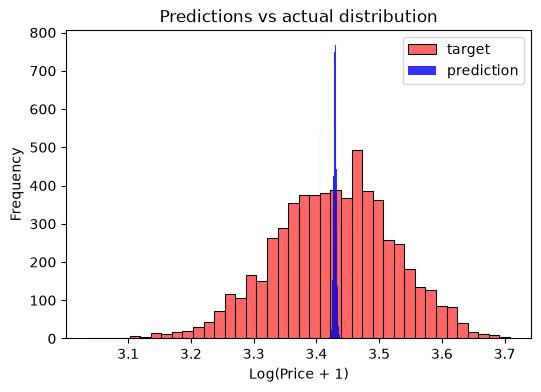

In [72]:
plt.figure(figsize=(6, 4))

sns.histplot(y_train, label='target', color='red', alpha=0.6, bins=40)
sns.histplot(y_pred, label='prediction', color='blue', alpha=0.8, bins=40)

plt.legend()

plt.ylabel('Frequency')
plt.xlabel('Log(Price + 1)')
plt.title('Predictions vs actual distribution')

plt.show()

In [80]:
rmse1(X_train, y_test)

np.float64(240.55842405979712)